In [2]:
import os
import pandas as pd
import urllib.request
from pymatgen.core import Structure
from sklearn.model_selection import train_test_split

print("1. Loading Matbench dataset...")
file_path = r"C:\Btech\SEM5\cuda\data_driven\matbench_mp_e_form.json\mp_e_form.json"
df = pd.read_json(file_path, orient="split")

print("2. Subsampling 100,000 structures...")
df_subset = df.sample(n=100000, random_state=42).reset_index(drop=True)

print("3. Splitting into Train (80%), Val (10%), Test (10%)...")
# First split: 80% Train, 20% Temp
train_df, temp_df = train_test_split(df_subset, test_size=0.20, random_state=42)
# Second split: Divide the 20% Temp equally into Val and Test
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42)

def generate_folder(dataframe, folder_name):
    os.makedirs(folder_name, exist_ok=True)
    id_prop_list = []
    print(f"Generating {len(dataframe)} files in '{folder_name}'...")
    
    for index, row in dataframe.iterrows():
        struct_dict = row['structure']
        structure = Structure.from_dict(struct_dict)
        material_id = f"mat_{index}"
        cif_filename = os.path.join(folder_name, f"{material_id}.cif")
        structure.to(fmt="cif", filename=cif_filename)
        id_prop_list.append([material_id, row['e_form']])
        
    pd.DataFrame(id_prop_list).to_csv(os.path.join(folder_name, "id_prop.csv"), index=False, header=False)
    
    # Download atom_init.json to each folder
    atom_init_url = "https://raw.githubusercontent.com/txie-93/cgcnn/master/data/sample-regression/atom_init.json"
    urllib.request.urlretrieve(atom_init_url, os.path.join(folder_name, "atom_init.json"))

# Execute the generation
generate_folder(train_df, "train_data")
generate_folder(val_df, "val_data")
generate_folder(test_df, "test_data")

print("Data generation complete!")

1. Loading Matbench dataset...
2. Subsampling 100,000 structures...
3. Splitting into Train (80%), Val (10%), Test (10%)...
Generating 80000 files in 'train_data'...
Generating 10000 files in 'val_data'...
Generating 10000 files in 'test_data'...
Data generation complete!


In [ ]:
import torch

# This should print True and your RTX 4060
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [3]:
import subprocess
import sys
import re

print("Starting CGCNN Training.")


# Run main.py for exactly 20 epochs using the current Python environment
python_executable = sys.executable
process = subprocess.Popen(
    [python_executable, "-W", "ignore", "main.py", "dummy_path", "--epochs", "20", "--batch-size", "256"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

current_epoch = 0
current_train_mae = 0.0
total_epochs = 20

# Read the raw output in real-time
with open("training_log.txt", "w") as log_file:
    for line in process.stdout:
        # Save everything to the log file for your plots later
        log_file.write(line)
        
        # Look for the Training MAE 
        train_match = re.search(r'Epoch: \[(\d+)\].*MAE \d+\.\d+ \((\d+\.\d+)\)', line)
        if train_match:
            current_epoch = int(train_match.group(1)) + 1  # Make it 1-indexed (1 to 20)
            current_train_mae = float(train_match.group(2))
            
        # Look for the Validation MAE 
        val_match = re.search(r'\* MAE (\d+\.\d+)', line)
        if val_match:
            val_mae = float(val_match.group(1))
            
            print(f"Epoch {current_epoch:02d}/{total_epochs} | Train MAE: {current_train_mae:.4f} eV/atom | Val MAE: {val_mae:.4f} eV/atom")

process.wait()
print("\nTraining complete! The best model is safely saved as 'model_best.pth.tar'.")

Starting CGCNN Training.
Epoch 01/20 | Train MAE: 0.2890 eV/atom | Val MAE: 0.1870 eV/atom
Epoch 02/20 | Train MAE: 0.1870 eV/atom | Val MAE: 0.1560 eV/atom
Epoch 03/20 | Train MAE: 0.1760 eV/atom | Val MAE: 0.1340 eV/atom
Epoch 04/20 | Train MAE: 0.1630 eV/atom | Val MAE: 0.1160 eV/atom
Epoch 05/20 | Train MAE: 0.1490 eV/atom | Val MAE: 0.2380 eV/atom
Epoch 06/20 | Train MAE: 0.1390 eV/atom | Val MAE: 0.1250 eV/atom
Epoch 07/20 | Train MAE: 0.1310 eV/atom | Val MAE: 0.1260 eV/atom
Epoch 08/20 | Train MAE: 0.1280 eV/atom | Val MAE: 0.1070 eV/atom
Epoch 09/20 | Train MAE: 0.1250 eV/atom | Val MAE: 0.1230 eV/atom
Epoch 10/20 | Train MAE: 0.1220 eV/atom | Val MAE: 0.1870 eV/atom
Epoch 11/20 | Train MAE: 0.1150 eV/atom | Val MAE: 0.0960 eV/atom
Epoch 12/20 | Train MAE: 0.1120 eV/atom | Val MAE: 0.1170 eV/atom
Epoch 13/20 | Train MAE: 0.1100 eV/atom | Val MAE: 0.1040 eV/atom
Epoch 14/20 | Train MAE: 0.1060 eV/atom | Val MAE: 0.0990 eV/atom
Epoch 15/20 | Train MAE: 0.1080 eV/atom | Val MAE: 

In [8]:
import warnings
warnings.filterwarnings('ignore') 

import torch
import pandas as pd
from torch.utils.data import DataLoader
from cgcnn.data import CIFData, collate_pool
from cgcnn.model import CrystalGraphConvNet

print("1. Loading Test Dataset...")
# Point PyTorch explicitly at your isolated test folder
test_dataset = CIFData('test_data')
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, collate_fn=collate_pool)

print("2. Loading Trained Model...")
# Load the saved model weights 
checkpoint = torch.load(r'C:\Btech\SEM5\cuda\data_driven\model_best.pth.tar', map_location='cuda', weights_only=False)

# Extract the original architecture settings
model_args = checkpoint['args']
structures, _, _ = test_dataset[0]
orig_atom_fea_len = structures[0].shape[-1]
nbr_fea_len = structures[1].shape[-1]

# Rebuild the empty PyTorch model architecture
model = CrystalGraphConvNet(
    orig_atom_fea_len, nbr_fea_len,
    atom_fea_len=model_args['atom_fea_len'],
    n_conv=model_args['n_conv'],
    h_fea_len=model_args['h_fea_len'],
    n_h=model_args['n_h'],
    classification=False
)

# Inject your trained weights into the model
model.load_state_dict(checkpoint['state_dict'])
model.cuda()
model.eval()

# Build a Normalizer to convert the raw neural network output back into eV/atom
class Normalizer(object):
    def __init__(self, tensor):
        self.mean = torch.mean(tensor)
        self.std = torch.std(tensor)
    def load_state_dict(self, state_dict):
        # FIX: Force the mean and std to be on the CPU so they match the output
        self.mean = state_dict['mean'].cpu()
        self.std = state_dict['std'].cpu()
    def denorm(self, x):
        return x * self.std + self.mean

normalizer = Normalizer(torch.zeros(3))
normalizer.load_state_dict(checkpoint['normalizer'])

print("3. Running GPU Predictions on Unseen Data...")
test_targets = []
test_preds = []
test_cif_ids = []

# Disable gradient tracking to max out testing speed
with torch.no_grad(): 
    for i, (input, target, batch_cif_ids) in enumerate(test_loader):
        
        # Move inputs to GPU memory
        input_var = (input[0].cuda(), input[1].cuda(), input[2].cuda(), [crys_idx.cuda() for crys_idx in input[3]])
        
        # Make the prediction
        output = model(*input_var)
        
        # Un-normalize the prediction to get the real energy value
        pred = normalizer.denorm(output.data.cpu())
        
        # Store the results
        test_targets.extend(target.view(-1).tolist())
        test_preds.extend(pred.view(-1).tolist())
        test_cif_ids.extend(batch_cif_ids)

# 4. Save results to CSV for  plotting dashboard
results_df = pd.DataFrame({
    'cif_id': test_cif_ids,
    'target': test_targets,
    'prediction': test_preds
})
results_df.to_csv('test_results.csv', index=False, header=False)

print("Success! Testing loop complete and 'test_results.csv' is ready.")

1. Loading Test Dataset...
2. Loading Trained Model...
3. Running GPU Predictions on Unseen Data...
Success! Testing loop complete and 'test_results.csv' is ready.


Parsing training logs and calculating final metrics...

       FINAL TEST SET METRICS
Mean Absolute Error (MAE):  0.0765 eV/atom
Root Mean Squared (RMSE):   0.1220 eV/atom
Max Absolute Error:         1.3861 eV/atom
R-squared (R²) Score:       0.9891



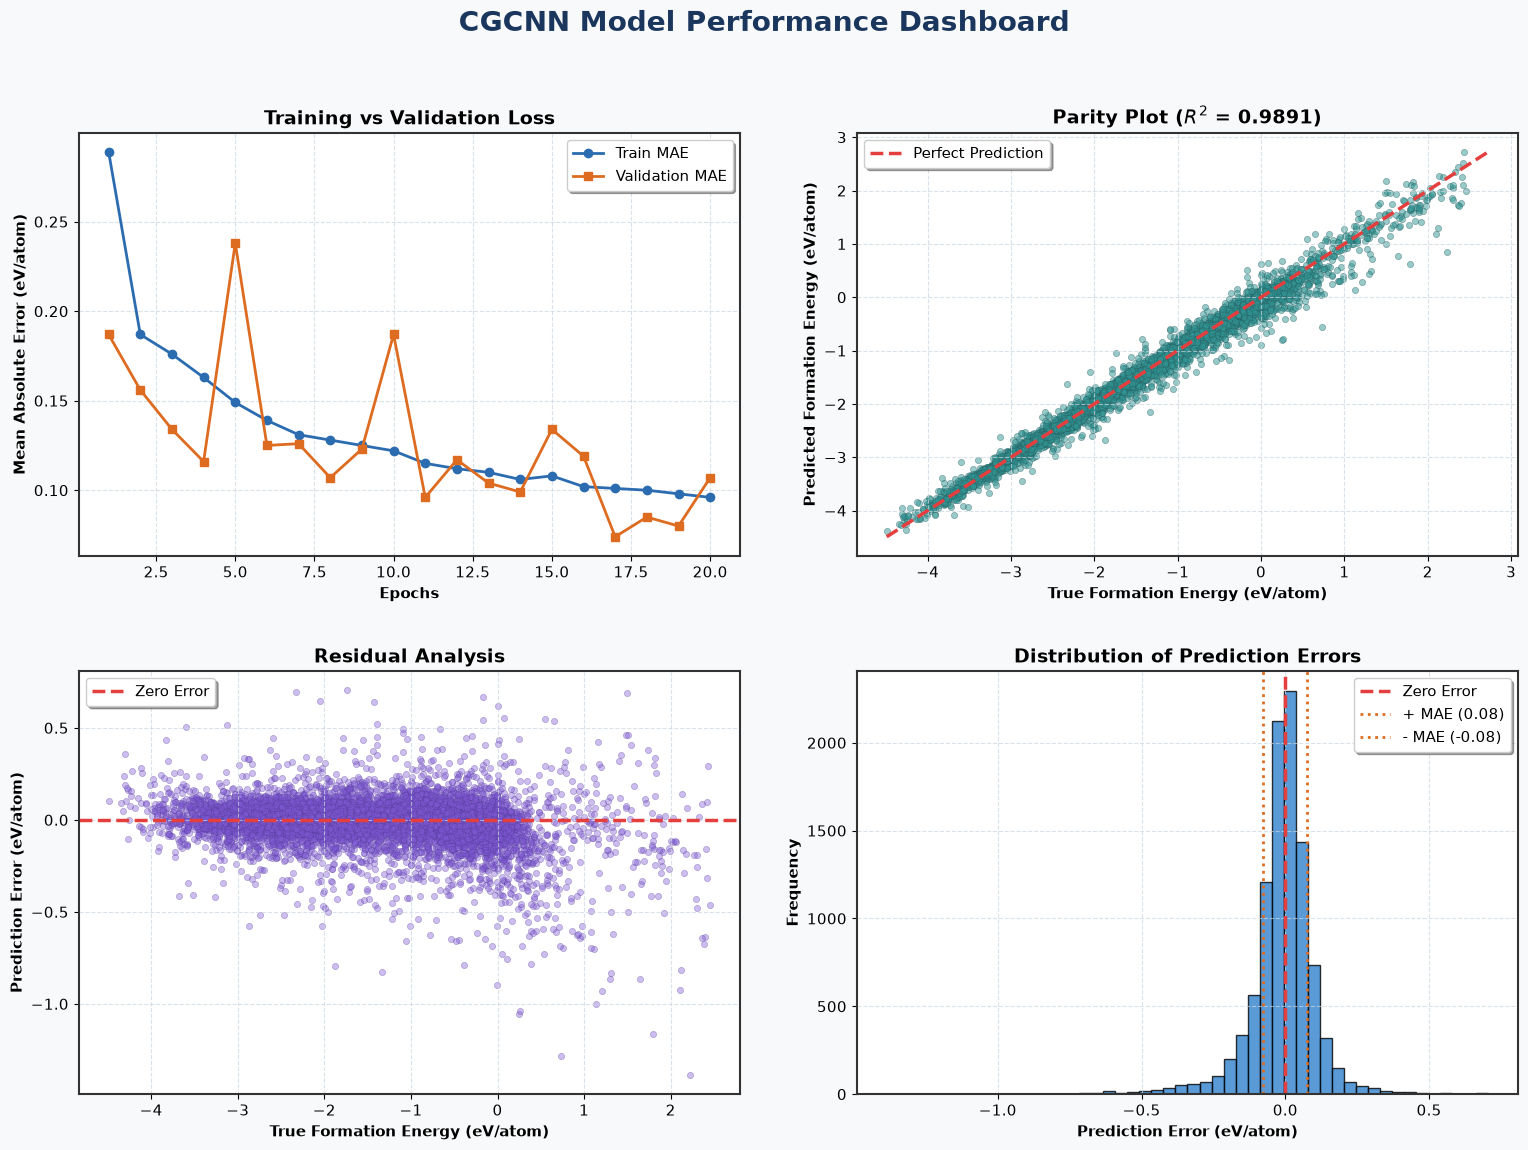


   ACTUAL VS PREDICTED (TOP 15 SAMPLES)


,Material ID,Actual (eV),Predicted (eV),Error (eV)
0,mat_57515,-0.3191,-0.5012,0.1822
1,mat_47884,-1.8695,-1.7439,0.1256
2,mat_54687,-0.0637,-0.3086,0.2449
3,mat_5276,-2.5627,-2.5259,0.0368
4,mat_98569,-1.5859,-1.3844,0.2015
5,mat_52759,-2.7511,-2.5570,0.1941
6,mat_73504,-2.5100,-2.4860,0.0240
7,mat_58131,-2.9860,-3.0367,0.0507
8,mat_74607,-1.7193,-1.7518,0.0325
9,mat_93575,-2.3934,-2.3771,0.0163


In [9]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Parsing training logs and calculating final metrics...\n")


# 1. PARSE TRAINING LOGS

train_mae_history = []
val_mae_history = []
current_epoch_train = []

try:
    with open("training_log.txt", "r") as f:
        lines = f.readlines()

    for line in lines:
        if "Epoch:" in line and "MAE" in line:
            match = re.search(r'MAE \d+\.\d+ \((\d+\.\d+)\)', line)
            if match:
                current_epoch_train.append(float(match.group(1)))
                
        if " * MAE" in line:
            val_mae = float(line.split()[-1])
            val_mae_history.append(val_mae)
            if current_epoch_train:
                train_mae_history.append(current_epoch_train[-1])
                current_epoch_train = []
except FileNotFoundError:
    print("Warning: 'training_log.txt' not found. Learning curve will be empty.")


# 2. LOAD TEST PREDICTIONS & CALCULATE METRICS

results = pd.read_csv("test_results.csv", header=None, names=["Material_ID", "True_Energy", "Predicted_Energy"])
results["Error"] = results["Predicted_Energy"] - results["True_Energy"]
results["Abs_Error"] = results["Error"].abs()

# Calculate comprehensive metrics
mae = mean_absolute_error(results["True_Energy"], results["Predicted_Energy"])
mse = mean_squared_error(results["True_Energy"], results["Predicted_Energy"])
rmse = np.sqrt(mse)
r2 = r2_score(results["True_Energy"], results["Predicted_Energy"])
max_error = results["Abs_Error"].max()

print("==========================================")
print("       FINAL TEST SET METRICS")
print("==========================================")
print(f"Mean Absolute Error (MAE):  {mae:.4f} eV/atom")
print(f"Root Mean Squared (RMSE):   {rmse:.4f} eV/atom")
print(f"Max Absolute Error:         {max_error:.4f} eV/atom")
print(f"R-squared (R²) Score:       {r2:.4f}")
print("==========================================\n")


# 3. CREATE THE CUSTOMIZED DASHBOARD

# Set global style parameters for a professional look
plt.rcParams.update({
    'font.size': 11,
    'axes.linewidth': 1.5,
    'axes.edgecolor': '#333333',
    'axes.labelweight': 'bold',
    'figure.facecolor': '#F8F9FA'
})

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('CGCNN Model Performance Dashboard', fontsize=20, fontweight='bold', color='#1A365D', y=0.98)

# --- Plot 1: Learning Curve ---
ax1 = axes[0, 0]
if train_mae_history and val_mae_history:
    epochs = range(1, len(train_mae_history) + 1)
    ax1.plot(epochs, train_mae_history, label='Train MAE', color='#2B6CB0', marker='o', linewidth=2, markersize=6)
    ax1.plot(epochs, val_mae_history, label='Validation MAE', color='#DD6B20', marker='s', linewidth=2, markersize=6)
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Mean Absolute Error (eV/atom)')
    ax1.set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
    ax1.legend(frameon=True, shadow=True)
    ax1.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')
else:
    ax1.text(0.5, 0.5, 'Log data not available', ha='center', va='center')

# --- Plot 2: Parity Plot (Actual vs Predicted) ---
ax2 = axes[0, 1]
ax2.scatter(results["True_Energy"], results["Predicted_Energy"], alpha=0.5, color='#319795', s=20, edgecolor='#285E61', linewidth=0.5)
min_val = min(results["True_Energy"].min(), results["Predicted_Energy"].min())
max_val = max(results["True_Energy"].max(), results["Predicted_Energy"].max())
ax2.plot([min_val, max_val], [min_val, max_val], color='#E53E3E', linestyle='--', linewidth=2.5, label='Perfect Prediction')
ax2.set_xlabel('True Formation Energy (eV/atom)')
ax2.set_ylabel('Predicted Formation Energy (eV/atom)')
ax2.set_title(f'Parity Plot ($R^2$ = {r2:.4f})', fontsize=14, fontweight='bold')
ax2.legend(frameon=True, shadow=True)
ax2.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')

# --- Plot 3: Residual Plot (Error vs True Value) ---
ax3 = axes[1, 0]
ax3.scatter(results["True_Energy"], results["Error"], alpha=0.4, color='#805AD5', s=20, edgecolor='#553C9A', linewidth=0.5)
ax3.axhline(y=0, color='#E53E3E', linestyle='--', linewidth=2.5, label='Zero Error')
ax3.set_xlabel('True Formation Energy (eV/atom)')
ax3.set_ylabel('Prediction Error (eV/atom)')
ax3.set_title('Residual Analysis', fontsize=14, fontweight='bold')
ax3.legend(frameon=True, shadow=True)
ax3.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')

# --- Plot 4: Error Distribution Histogram ---
ax4 = axes[1, 1]
counts, bins, patches = ax4.hist(results["Error"], bins=50, color='#3182CE', edgecolor='black', alpha=0.8)
ax4.axvline(x=0, color='#E53E3E', linestyle='--', linewidth=2.5, label='Zero Error')
# Add MAE boundaries
ax4.axvline(x=mae, color='#DD6B20', linestyle=':', linewidth=2, label=f'+ MAE ({mae:.2f})')
ax4.axvline(x=-mae, color='#DD6B20', linestyle=':', linewidth=2, label=f'- MAE ({-mae:.2f})')
ax4.set_xlabel('Prediction Error (eV/atom)')
ax4.set_ylabel('Frequency')
ax4.set_title('Distribution of Prediction Errors', fontsize=14, fontweight='bold')
ax4.legend(frameon=True, shadow=True)
ax4.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')

plt.tight_layout(pad=3.0)
plt.show()

# 4. DISPLAY ACTUAL VS PREDICTED TABLE

print("\n==========================================")
print("   ACTUAL VS PREDICTED (TOP 15 SAMPLES)")
print("==========================================")
# Format the dataframe for a clean output display
display_df = results[['Material_ID', 'True_Energy', 'Predicted_Energy', 'Abs_Error']].copy()
display_df.columns = ['Material ID', 'Actual (eV)', 'Predicted (eV)', 'Error (eV)']
# If using Jupyter Notebook, 'display' makes a beautiful HTML table. 
# If running in a script, it falls back to print.
try:
    display(display_df.head(15).round(4))
except NameError:
    print(display_df.head(15).round(4).to_string(index=False))